In [ ]:
# an initial test into differences in TC Beyrl 

In [1]:
import numpy as np 
import os 
import xarray as xr
import pandas as pd

from scipy.stats import wilcoxon
from scipy.stats import norm
#import regionmask 
#import geopandas as gp
import seaborn as sns
import cmocean 
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.projections import PolarAxes
import mpl_toolkits.axisartist.floating_axes as fa
import mpl_toolkits.axisartist.grid_finder as gf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import matplotlib.colors as mcolors
import matplotlib
import matplotlib.tri as tri

import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.patches import Rectangle

from scipy.stats import spearmanr

from dask.distributed import Client, LocalCluster
import matplotlib.gridspec as gs
from matplotlib.colors import LogNorm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import colors

# use metpy to calculate relative humidity
from metpy.calc import dewpoint_from_relative_humidity
from metpy.calc import cape_cin
from metpy.calc import lcl

import time
#import easygems.healpix as egh
import cartopy.feature as cf
import healpy as hp
from metpy.calc import cape_cin, dewpoint_from_relative_humidity, parcel_profile
from metpy.units import units

# import aqua
# from aqua import Reader
# from aqua.util import area_selection
# from gsv import GSVRetriever
# from gsv.requests.parser import parse_request
# from gsv.requests.utils import convert_to_step_format

#os.chdir("/home/b/b382291/git/gloria_storm/")
#os.chdir("/users/kgrayson/git/gloria_storm/")

# from gloria_functions import closest_value
# from gloria_functions import create_catalan_mask
# from gloria_functions import convert_tp
# from gloria_functions import convert_mtpr
# from gloria_functions import convert_prlr
# from gloria_functions import compute_ivt
# from gloria_functions import TaylorDiagram
# from gloria_functions import fix_aqua_coords
# from gloria_functions import fix_coords_era5
# from gloria_functions import shiftedColorMap
# from gloria_functions import ticks_round
# from gloria_functions import create_land_mask
# from gloria_functions import create_spain_mask
# from gloria_functions import crop_to_ES_box
# from gloria_functions import crop_to_cities
# from gloria_functions import crop_to_city_nat
# from gloria_functions import crop_to_box_nat
# from gloria_functions import take_spatial_average
# from gloria_functions import convert_mtpr_tp
# from gloria_functions import convert_prlr_tp
# from gloria_functions import obs_cities
!hostname
#print(aqua.__version__)

from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")



/home/b/b382291/.conda/envs/aqua_26/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


l40076.lvt.dkrz.de


In [ ]:
# # running pyhanami 

# g0 = 9.80665
# years = pd.date_range(start="2018", end="2025", freq='YE')
# years = years.strftime('%Y').tolist()

# exps = ["cont", "hist", "Tplus2.0K"]
# for exp in exps:
#     for year in years:
#         ds_msl = xr.open_mfdataset(f'/scratch/b/b382291/caribbean/storylines/{exp}/member_1/annual/msl_u10_v10_{year}_01_01_to_{year}_12_31.nc')
#         ds_z = xr.open_mfdataset(f'/scratch/b/b382291/caribbean/storylines/{exp}/member_1/annual/z_{year}_01_01_to_{year}_12_31.nc')

#         final_path = f'/scratch/b/b382291/caribbean/storylines/{exp}/member_1/psl_uas_vas_z_{year}.nc'

#         # Check the level dimension name and values first
#         print(ds_z.z.dims, ds_z.z.attrs.get('units'))
#         lev_dim = [d for d in ds_z.z.dims if d not in ('time', 'lat', 'lon', 'latitude', 'longitude')][0]
#         print(lev_dim, ds_z[lev_dim].values)

#         def to_latlon(ds):
#             mapping = {k: v for k, v in {'latitude': 'lat', 'longitude': 'lon'}.items() if k in ds.dims or k in ds.coords}
#             return ds.rename(mapping)

#         ds_msl = to_latlon(ds_msl)
#         ds_z = to_latlon(ds_z)


#         # Geopotential -> geopotential height
#         zg = ds_z['z'] / g0

#         # One DataArray per level: zg300, zg500, ...
#         zg_vars = {}
#         for lev in zg[lev_dim].values:
#             name = f"zg{int(lev)}"
#             da = zg.sel({lev_dim: lev}, drop=True)
#             da.attrs = {
#                 'long_name': f'Geopotential height at {int(lev)} hPa',
#                 'standard_name': 'geopotential_height',
#                 'units': 'm',
#             }
#             zg_vars[name] = da

#         ds_zg = xr.Dataset(zg_vars)

#         # change variable names for ds_msl
#         ds_msl = ds_msl.rename({'msl': 'psl'})
#         ds_msl = ds_msl.rename({'10v': 'vas'})
#         ds_msl = ds_msl.rename({'10u': 'uas'})

#         ds_msl['psl'].attrs.update(
#             long_name='Sea level pressure',
#             standard_name='air_pressure_at_mean_sea_level',
#         )
#         ds_msl['vas'].attrs.update(
#             long_name='Northward near-surface wind',
#         )
#         ds_msl['uas'].attrs.update(
#             long_name='Eastward near-surface wind',
#         )
#         # Merge: all 5 variables (msl, u10, v10, zg_a, zg_b) on the same dims
#         ds = xr.merge([ds_msl, ds_zg], join='exact')

#         ds.to_netcdf(path = final_path, mode = 'w')


In [2]:
# read the data for 2024 

###################33 PRECIPITATION #####################################
#### import data from DestinE and from CORDEX

diff = 273.15 

# root_noaa =  "/work/bb1153/b382291/caribbean/noaa_oisstv2"
# root_esa = "/work/bb1153/b382291/caribbean/esa_sstcci"
# root_ifs_nemo = "/work/bb1153/b382291/caribbean/IFS-NEMO/0.1"
# root_ifs_fesom = "/work/bb1153/b382291/caribbean/IFS-FESOM/0.1"
# root_icon = "/work/bb1153/b382291/caribbean/ICON/0.1"

storyline_data_path = "/scratch/b/b382291/caribbean/storylines"
# root_mswep = "/gpfs/scratch/bsc32/bsc032263/mswep"
# root_era5_land = "/gpfs/scratch/bsc32/bsc032263/era5land"
# root_cimh = "/gpfs/scratch/bsc32/bsc032263/cimh"

islands_all = ["caribbean_islands"] 
islands_all_short = ["car"] 

In [6]:

################################ load destinE data ###############################################
vars = "psl_uas_vas_z"

variables = ["psl", "uas", "vas", "zg300", "zg500"]
exps = ["cont", "hist"] # need to readd Tplus2.0K 

time_start = "28-06-2024"
time_end = "11-07-2024"

ensembles = [1]

for experiment in exps:
    for ensemble in ensembles:
    
        path = f"{storyline_data_path}/{experiment}/member_{ensemble}/{vars}_2024.nc"
        ds = xr.open_dataset(path)
    
        for variable in variables:
            var_name = f"{variable}_{experiment}_mem_{ensemble}"
            da = ds[f'{variable}']
            da = da.sel(time = slice(time_start, time_end))
            globals()[var_name] = da
            print(var_name)



psl_cont_mem_1
uas_cont_mem_1
vas_cont_mem_1
zg300_cont_mem_1
zg500_cont_mem_1
psl_hist_mem_1
uas_hist_mem_1
vas_hist_mem_1
zg300_hist_mem_1
zg500_hist_mem_1


In [ ]:
# cut the dates for TC beryl 

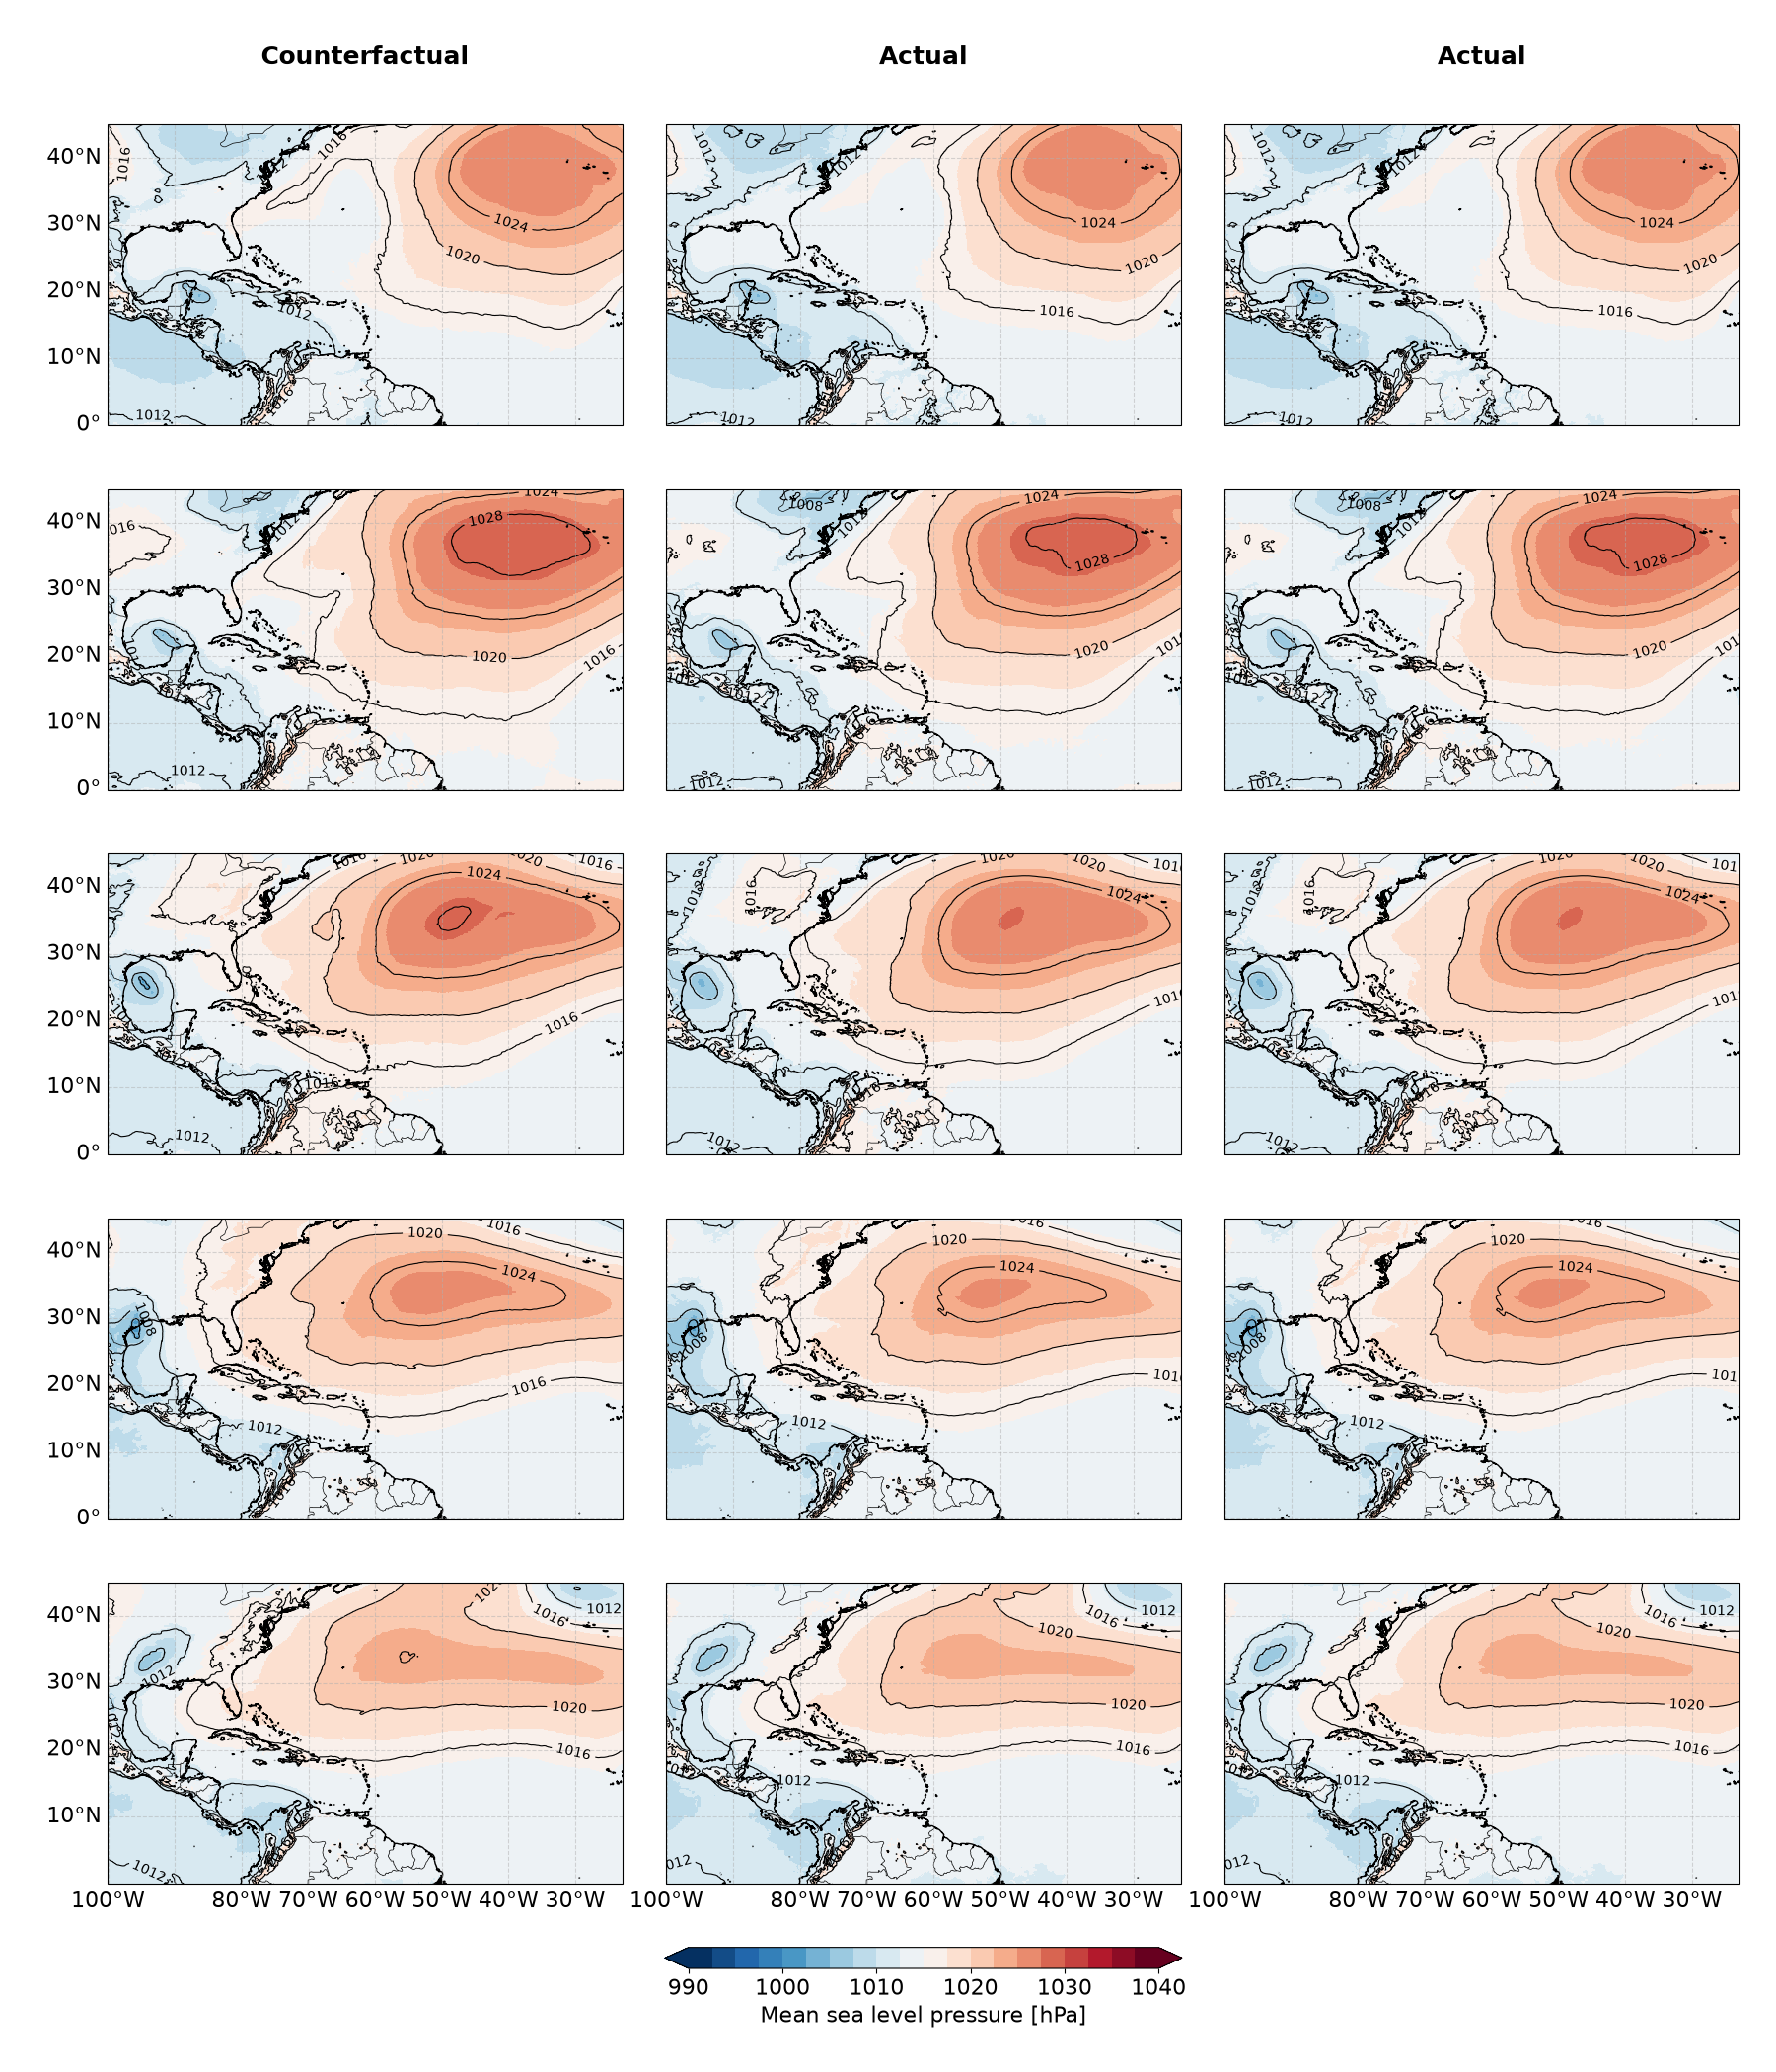

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.colors import ListedColormap
import cartopy.crs as ccrs
import cartopy.feature as cfeature


%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}

# ----------------------------------------------------------------------------
# Settings
# ----------------------------------------------------------------------------
projection = ccrs.PlateCarree()

nrow = 5                      # one row per date
ncol = 3                      # one column per scenario
fsize = 16

scenarios = ["cont", "hist", "hist"]
scenario_names = {            # column headers, edit as you like
    "cont": "Counterfactual",
    "hist": "Actual",
    "Tplus2.0K": "+2.0 K",
}

ensemble = 1                  # member used (variables are named psl_{exp}_mem_{ensemble})

start_date = pd.Timestamp("2024-07-05")
step_days = 1                 # each row is 3 days after the previous one
dates = [start_date + pd.Timedelta(days=step_days * r) for r in range(nrow)]
# -> 28 Jun, 1 Jul, 4 Jul, 7 Jul, 10 Jul (all inside the 28-06 to 11-07 window)

# Optional map extent [lon_min, lon_max, lat_min, lat_max]; None = full data domain
extent = None
# extent = [-100, -40, 5, 35]

# Colours and levels (psl in hPa)
min_value = 990
max_value = 1040
fill_step = 2.5
contour_step = 4
contour_levels = np.arange(980, 1048 + contour_step, contour_step)

cmap = plt.get_cmap("RdBu_r")
n_colors = int((max_value - min_value) / fill_step)
cmap = ListedColormap(cmap(np.linspace(0, 1, n_colors)))

labels = [f"({chr(97 + k)})" for k in range(nrow * ncol)]   # (a), (b), ... (o)


# ----------------------------------------------------------------------------
# Helper: daily-mean psl in hPa for a given scenario and date
# ----------------------------------------------------------------------------
def get_psl_day(scenario, date, member=ensemble):
    da = globals()[f"psl_{scenario}_mem_{member}"]
    day = da.sel(time=slice(date, date + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)))
    return day.mean("time") / 100.0       # Pa -> hPa


# Grid taken from the first field (assumes all scenarios share the same grid)
ref = get_psl_day(scenarios[0], dates[0])
lons, lats = np.meshgrid(ref.lon.values, ref.lat.values)


# ----------------------------------------------------------------------------
# Figure
# ----------------------------------------------------------------------------
fig = plt.figure(figsize=(6 * ncol, 4.2 * nrow), constrained_layout=False)
# extra thin row at the bottom is reserved for the colorbar
gs = gridspec.GridSpec(nrow + 1, ncol, figure=fig,
                       height_ratios=[1] * nrow + [0.07], width_ratios=[1] * ncol,
                       hspace=0.25, wspace=0.08,
                       top=0.94, bottom=0.05, left=0.06, right=0.98)

label_count = 0

# Shared colorbar
cbar_ax = fig.add_subplot(gs[nrow, 1])          # middle column of the extra row
# ticks = np.arange(min_value, max_value + 1, 10)
# cbar = fig.colorbar(pcm, cax=cbar_ax, orientation="horizontal",
#                     ticks=ticks, extend="both")
# cbar.ax.tick_params(labelsize=fsize)
# cbar.set_label("Mean sea level pressure [hPa]", fontsize=fsize)


for i in range(nrow * ncol):

    row = np.floor_divide(i, ncol)
    col = np.mod(i, ncol)

    scenario = scenarios[col]
    date = dates[row]

    ax = fig.add_subplot(gs[row, col], projection=projection)

    to_plot = get_psl_day(scenario, date)

    pcm = ax.pcolormesh(lons, lats, to_plot, transform=projection, cmap=cmap,
                        shading="auto", vmin=min_value, vmax=max_value)

    contours = ax.contour(ref.lon.values, ref.lat.values, to_plot,
                          levels=contour_levels, colors="black",
                          linewidths=0.8, transform=projection)
    ax.clabel(contours, inline=True, fontsize=10, fmt="%d")

    # Date above each sub figure
    ax.set_title(rf"$\mathbf{{{labels[label_count]}}}$ {date.strftime('%d %b %Y')}",
                 fontsize=fsize)
    label_count += 1

    # Scenario name as a column header above the top row
    if row == 0:
        ax.text(0.5, 1.18, scenario_names[scenario], transform=ax.transAxes,
                ha="center", va="bottom", fontsize=fsize + 2, fontweight="bold")

    if extent is not None:
        ax.set_extent(extent, crs=projection)

    # Gridlines: latitude labels on the first column, longitude labels on the last row
    gl = ax.gridlines(draw_labels=True, linestyle="dashed", alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = (col == 0)
    gl.bottom_labels = (row == nrow - 1)
    gl.xlabel_style = {"size": fsize}
    gl.ylabel_style = {"size": fsize}

    ax.coastlines(resolution="10m", color="black", linewidth=1)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)

# Shared colorbar
#cbar_ax = fig.add_subplot(gs[nrow, 1])          # middle column of the extra row
ticks = np.arange(min_value, max_value + 1, 10)
cbar = fig.colorbar(pcm, cax=cbar_ax, orientation="horizontal",
                    ticks=ticks, extend="both")
cbar.ax.tick_params(labelsize=fsize)
cbar.set_label("Mean sea level pressure [hPa]", fontsize=fsize)

# file_path = f"/work/bb1153/b382291/gloria/figs/storyline_psl_mem_{ensemble}.png"
# plt.savefig(file_path, dpi=200, bbox_inches="tight")

# plt.show()
# plt.close(fig)